# FD001 - Sensor exploration and measured results

This report reads the current data and trained artifacts. **All performance tables and plots come from generated CSV/JSON files; no model scores are hard-coded.**

First run `Training.ipynb`, stage notebooks 02-05, or `uv run pm-train`. Figures are exported to the repository's `reports/figures/` directory. RUL is capped consistently with training, and model selection uses training cross-validation rather than test scores.


In [1]:
from pathlib import Path
import os
import sys

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").is_file()
     and (path / "src" / "predictive_maintenance").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from the project root or its notebooks directory.")
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("PM_PROJECT_ROOT", str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import display
from loguru import logger
from predictive_maintenance.config import (
    EXTERNAL_DATA_DIR, RAW_DATA_DIR, INTERIM_DATA_DIR,
    PROCESSED_DATA_DIR, MODELS_DIR, RESULTS_DIR, FIGURES_DIR,
    RUL_CAP, TREND_WINDOW, SETTINGS,
)

logger.remove()
logger.add(sys.stderr, level="WARNING")
pd.set_option("display.max_columns", 40)
print(f"Project: {ROOT.name} | Python: {sys.version.split()[0]}")


Project: Predictive-Maintenance-for-Sensor-Data | Python: 3.13.9


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from IPython import get_ipython

get_ipython().run_line_magic("matplotlib", "inline")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 100})
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


In [3]:
import json
from predictive_maintenance.models.predict import predict
from predictive_maintenance.models.evaluate import evaluate, align_predictions

required = [INTERIM_DATA_DIR / "train_preprocessed.csv", MODELS_DIR / "best_model.json",
            RESULTS_DIR / "model_comparison.csv", RESULTS_DIR / "test_evaluation.csv"]
if any(not path.exists() for path in required):
    raise FileNotFoundError("Run Training.ipynb or `uv run pm-train` before this report.")
train = pd.read_csv(INTERIM_DATA_DIR / "train_preprocessed.csv")
manifest = json.loads((MODELS_DIR / "best_model.json").read_text())
test_results = pd.read_csv(RESULTS_DIR / "test_evaluation.csv")
cv_results = pd.read_csv(RESULTS_DIR / "model_comparison.csv")
predictions_path = PROCESSED_DATA_DIR / "test_predictions.csv"
labels_path = PROCESSED_DATA_DIR / "test_labels.csv"
predict(MODELS_DIR / "best_model.json", PROCESSED_DATA_DIR / "test_features.csv", predictions_path)
evaluate(predictions_path, labels_path, RESULTS_DIR / "evaluation.csv", RESULTS_DIR / "evaluation_by_unit.csv")
joined = align_predictions(pd.read_csv(predictions_path), pd.read_csv(labels_path))
last = joined.loc[joined.groupby("unit").cycle.idxmax()].sort_values("unit")
print("Selected by validation:", manifest["model_name"])
print("Figures:", FIGURES_DIR.relative_to(ROOT))


Selected by validation: LightGBM
Figures: reports\figures


## Training engine lifetimes and capped targets


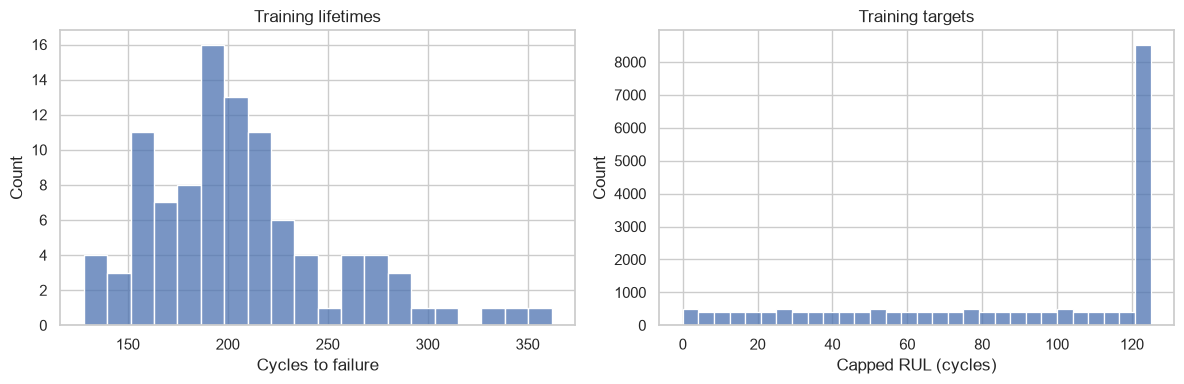

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train.groupby("unit").cycle.max(), bins=20, ax=axes[0])
axes[0].set(title="Training lifetimes", xlabel="Cycles to failure")
sns.histplot(train.RUL, bins=30, ax=axes[1])
axes[1].set(title="Training targets", xlabel="Capped RUL (cycles)")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "eda_lifetimes_rul.png", bbox_inches="tight")
plt.show()


## Sensor correlations and trajectories


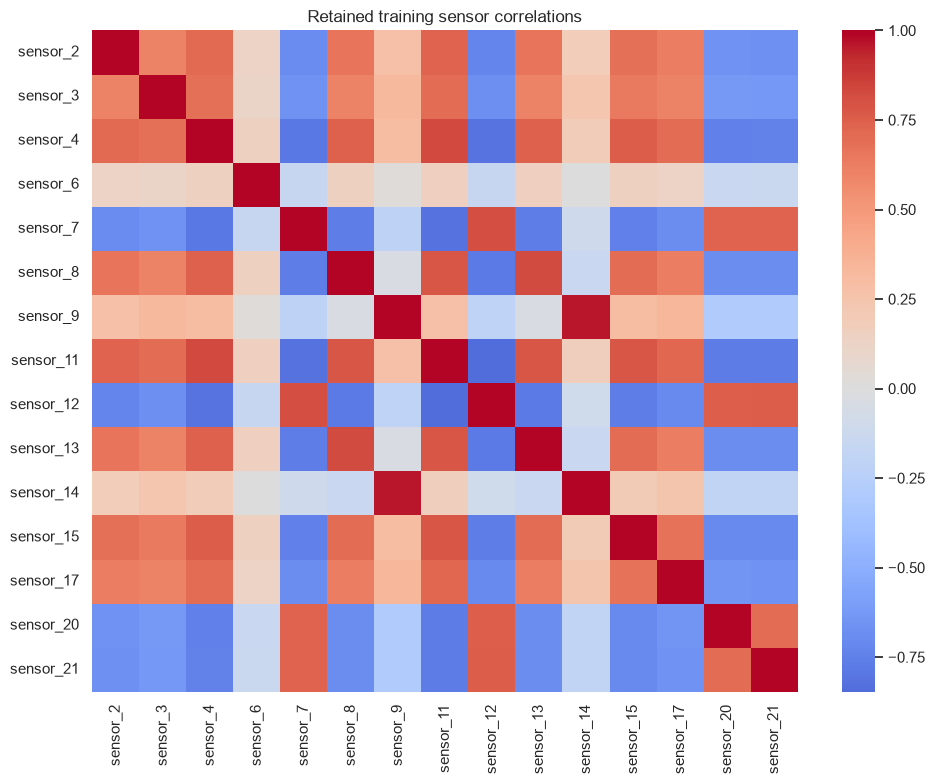

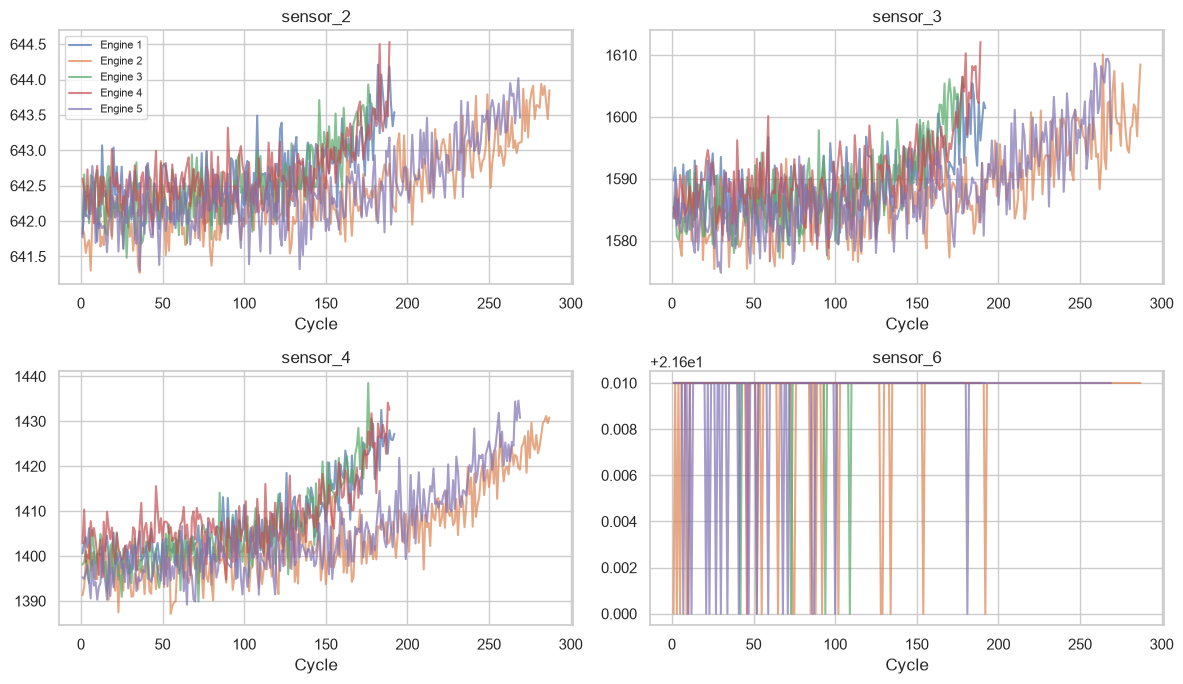

In [5]:
sensors = [name for name in train if name.startswith("sensor_")]
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(train[sensors].corr(), cmap="coolwarm", center=0, ax=ax)
ax.set_title("Retained training sensor correlations")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "eda_correlation_capteurs.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, sensor in zip(axes.flat, sensors[:4]):
    for unit in sorted(train.unit.unique())[:5]:
        history = train.loc[train.unit == unit].sort_values("cycle")
        ax.plot(history.cycle, history[sensor], label=f"Engine {unit}", alpha=0.7)
    ax.set(title=sensor, xlabel="Cycle")
axes.flat[0].legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "eda_sensor_trajectories.png", bbox_inches="tight")
plt.show()


## Engine-grouped cross-validation

Error bars show fold standard deviation. These all-cycle validation scores select the serving model.


,model,MAE_mean,MAE_std,RMSE_mean,RMSE_std
0,LightGBM,12.912403,1.198666,17.825632,1.524688
2,XGBoost,13.029350,1.230391,17.942778,1.547701
1,LinearRegression,16.967198,1.062759,20.920921,1.053402


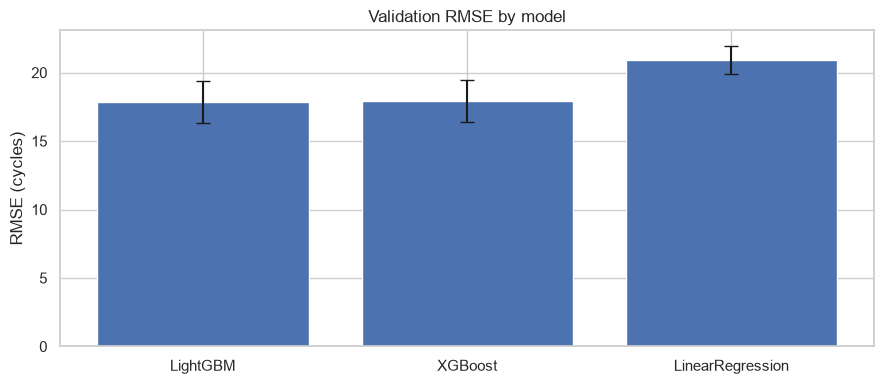

In [6]:
display(cv_results.sort_values("RMSE_mean"))
ordered = cv_results.sort_values("RMSE_mean")
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(ordered.model, ordered.RMSE_mean, yerr=ordered.RMSE_std, capsize=5)
ax.set(title="Validation RMSE by model", ylabel="RMSE (cycles)")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "groupkfold_rmse.png", bbox_inches="tight")
plt.show()


## Held-out final-cycle results

These scores evaluate each model once per test engine. Optional LSTM results appear only when that experiment was actually trained. Test performance does not promote a model.


,model,MAE,RMSE,n_engines
0,LightGBM,11.826881,16.377040,100
1,XGBoost,12.304318,16.527736,100
2,LinearRegression,16.021368,20.254767,100


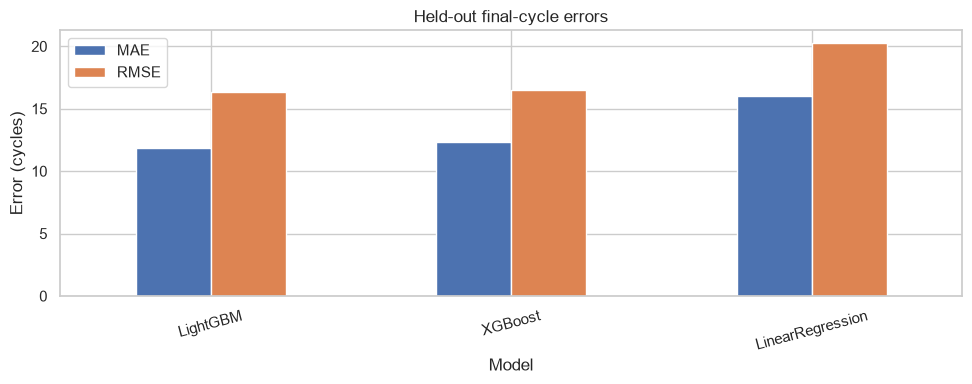

,MAE,RMSE,R2,PHM08,n_engines
0,11.826881,16.37704,0.832983,607.393744,100


In [7]:
display(test_results)
fig, ax = plt.subplots(figsize=(10, 4))
test_results.set_index("model")[["MAE", "RMSE"]].plot.bar(ax=ax, rot=15)
ax.set(title="Held-out final-cycle errors", ylabel="Error (cycles)", xlabel="Model")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "resultats_mae_rmse.png", bbox_inches="tight")
plt.show()
display(pd.read_csv(RESULTS_DIR / "evaluation.csv"))


## Selected model predictions and error distribution

PHM08 is reported for the selected model in the preceding table; model-wide PHM08 scores are not fabricated from MAE or RMSE.


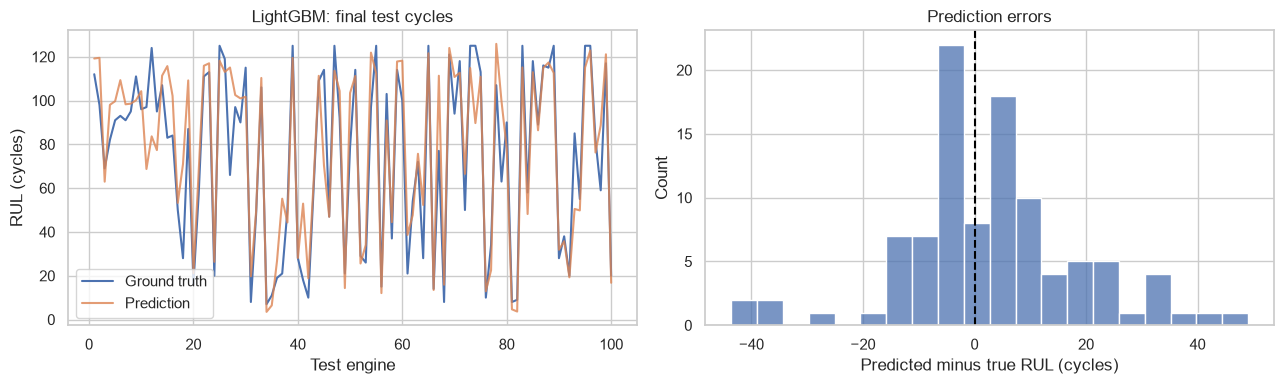

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(last.unit, last.RUL, label="Ground truth")
axes[0].plot(last.unit, last.prediction, label="Prediction", alpha=0.8)
axes[0].set(title=f"{manifest['model_name']}: final test cycles", xlabel="Test engine", ylabel="RUL (cycles)")
axes[0].legend()
sns.histplot(last.prediction - last.RUL, bins=20, ax=axes[1])
axes[1].axvline(0, linestyle="--", color="black")
axes[1].set(title="Prediction errors", xlabel="Predicted minus true RUL (cycles)")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "selected_model_predictions_residuals.png", bbox_inches="tight")
plt.show()


## Selected model feature importance

Tree importances describe fitted usage of a feature, not causal importance. Linear regression does not produce this tree-importance artifact.


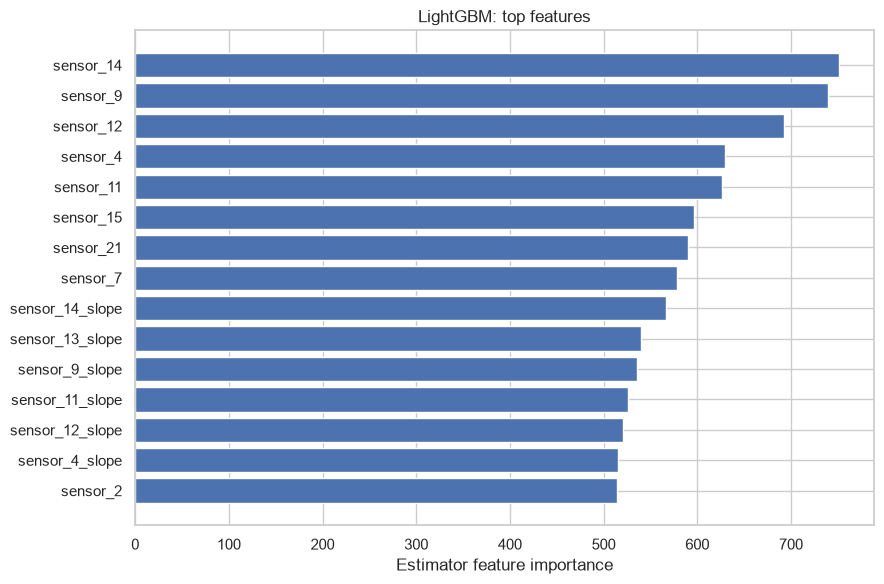

In [9]:
model_file = Path(manifest["files"].get("model", ""))
importance_path = MODELS_DIR / f"{model_file.stem}_feature_importance.csv"
if importance_path.exists():
    importance = pd.read_csv(importance_path).nlargest(15, "importance").sort_values("importance")
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(importance.feature, importance.importance)
    ax.set(title=f"{manifest['model_name']}: top features", xlabel="Estimator feature importance")
    plt.tight_layout()
    fig.savefig(FIGURES_DIR / "selected_model_feature_importance.png", bbox_inches="tight")
    plt.show()
else:
    print("The selected model has no saved tree feature-importance table.")


## Interpretation limits

Results describe the FD001 benchmark with capped targets, rather than guaranteed performance on other engine regimes or real deployments. Health classes in the API are RUL thresholds. Distribution drift diagnostics do not replace labelled online evaluation.
